In [9]:
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet, LogisticRegression
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm
import statsmodels.formula.api as smf
from itertools import product
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    mean_absolute_error, root_mean_squared_error, mean_squared_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, ConfusionMatrixDisplay,average_precision_score
)
from itertools import combinations
from scipy import sparse
from threadpoolctl import threadpool_limits

SEED = 42
SAMPLE_FRACTION = 1  # 0.05%
DATA_PATH = "datasets/NOAA_Weather/weather_cleaned.parquet"


In [2]:
parquet = pq.ParquetFile(DATA_PATH)
sample_size = round(parquet.metadata.num_rows * SAMPLE_FRACTION)
rng = np.random.default_rng(SEED)
positions = np.sort(rng.choice(parquet.metadata.num_rows, sample_size, replace=False))

parts = []
offset = 0
for group in range(parquet.num_row_groups):
    end = offset + parquet.metadata.row_group(group).num_rows
    rows = positions[(positions >= offset) & (positions < end)] - offset
    if len(rows):
        table = parquet.read_row_group(group)
        parts.append(table.take(rows).to_pandas())
    offset = end
sample = pd.concat(parts, ignore_index=True)
print(f"Sample: {len(sample):,} flights")

Sample: 5,828,408 flights


In [3]:

df = sample.loc[
    sample["airport_code"] == "ORD"
].copy()

df["timestamp_utc"] = pd.to_datetime(
    df["timestamp_utc"], utc=True
)

df = df.sort_values("timestamp_utc")
df["hour_utc"] = df["timestamp_utc"].dt.floor("h")

# Select last observation in each hour
df = df.drop_duplicates("hour_utc", keep="last")
df = df.set_index("hour_utc").asfreq("h")

# Create next-hour visibility
df["visibility_next_hour"] = df["visibility_km"].shift(-1)

# Exclude observations without current or future visibility
df = df.dropna(
    subset=["visibility_km", "visibility_next_hour"]
).copy()

# Binary target
df["low_visibility_next_hour"] = (
    df["visibility_next_hour"] < 5
).astype(int)

# Time features
local_time = df.index.tz_convert("America/Chicago")
df["month"] = local_time.month
df["hour_of_day"] = local_time.hour

print(df["low_visibility_next_hour"].value_counts(normalize=True))


low_visibility_next_hour
0    0.951439
1    0.048561
Name: proportion, dtype: float64


In [ ]:

df["low_visibility_next_hour"].value_counts(
    normalize=True
).mul(100).round(2)


low_visibility_next_hour
0    95.14
1     4.86
Name: proportion, dtype: float64

In [ ]:
numeric_features = [
    "visibility_km",
    "temperature_c",
    "dew_point_c",
    "wind_speed_m_s",
    "sea_level_pressure_hpa"
]

categorical_features = ["month", "hour_of_day"]
features = numeric_features + categorical_features

# Chronological train/test split
cutoff = pd.Timestamp("2024-01-01", tz="UTC")

# Keep training labels strictly before the test period
train = df.loc[df.index + pd.Timedelta(hours=1) < cutoff]
test = df.loc[df.index >= cutoff]

X_train = train[features]
y_train = train["low_visibility_next_hour"]

X_test = test[features]
y_test = test["low_visibility_next_hour"]

preprocessor = ColumnTransformer([
    ("numeric", make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler()
    ), numeric_features),

    ("categorical", OneHotEncoder(
        drop="first",
        handle_unknown="ignore"
    ), categorical_features)
])

logistic_model = make_pipeline(
    preprocessor,
    LogisticRegression(max_iter=1000)
)

logistic_model.fit(X_train, y_train)

# Predicted probabilities and classifications
y_prob = logistic_model.predict_proba(X_test)[:, 1]
y_pred = (y_prob >= 0.5).astype(int)


In [7]:
baseline = (X_test["visibility_km"] < 5).astype(int)

def evaluate_classification(actual, predicted):
    return {
        "Accuracy": accuracy_score(actual, predicted),
        "Precision": precision_score(
            actual, predicted, zero_division=0
        ),
        "Recall": recall_score(
            actual, predicted, zero_division=0
        ),
        "F1": f1_score(
            actual, predicted, zero_division=0
        )
    }

results = pd.DataFrame({
    "Persistence Baseline": evaluate_classification(
        y_test, baseline
    ),
    "Logistic Regression": evaluate_classification(
        y_test, y_pred
    )
}).T

display(results.round(4))

print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))
print("Average Precision:", round(
    average_precision_score(y_test, y_prob), 4
))


,Accuracy,Precision,Recall,F1
Persistence Baseline,0.9768,0.7055,0.7045,0.7050
Logistic Regression,0.9780,0.7488,0.6638,0.7037


ROC-AUC: 0.9613
Average Precision: 0.7611


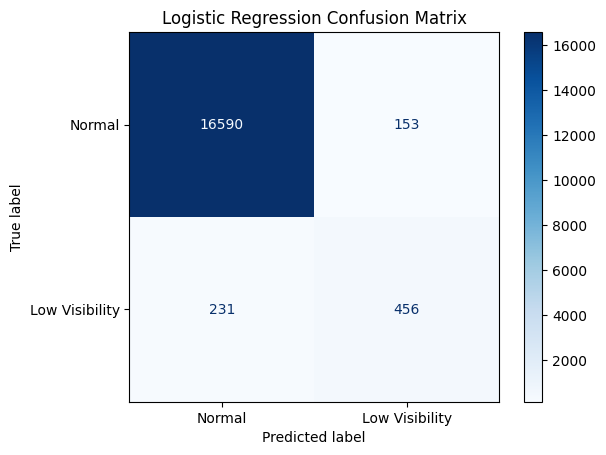

In [8]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Normal", "Low Visibility"],
    cmap="Blues"
)

plt.title("Logistic Regression Confusion Matrix")
plt.show()


In [10]:

from sklearn.base import clone
from sklearn.metrics import precision_score, recall_score, f1_score
import numpy as np
import pandas as pd

# Reserve 2023 for threshold selection
validation_start = pd.Timestamp("2023-01-01", tz="UTC")

# Keep training targets before the validation period
train_mask = (
    X_train.index + pd.Timedelta(hours=1)
    < validation_start
)
val_mask = X_train.index >= validation_start

X_dev = X_train.loc[train_mask]
y_dev = y_train.loc[train_mask]

X_val = X_train.loc[val_mask]
y_val = y_train.loc[val_mask]

# Train without the validation period
validation_model = clone(logistic_model)
validation_model.fit(X_dev, y_dev)

# Predict probabilities
val_prob = validation_model.predict_proba(X_val)[:, 1]

thresholds = np.arange(0.10, 0.91, 0.05)

results = []

for threshold in thresholds:
    predicted = (val_prob >= threshold).astype(int)

    results.append({
        "Threshold": round(threshold, 2),
        "Precision": precision_score(y_val, predicted, zero_division=0),
        "Recall": recall_score(y_val, predicted, zero_division=0),
        "F1": f1_score(y_val, predicted, zero_division=0)
    })

threshold_results = pd.DataFrame(results)

display(threshold_results.round(4))


,Threshold,Precision,Recall,F1
0,0.10,0.4837,0.8602,0.6193
1,0.15,0.5375,0.8289,0.6521
2,0.20,0.5857,0.8072,0.6788
3,0.25,0.6275,0.7711,0.6919
4,0.30,0.6530,0.7301,0.6894
5,0.35,0.6682,0.6988,0.6832
6,0.40,0.6925,0.6458,0.6683
7,0.45,0.7066,0.5976,0.6475
8,0.50,0.7117,0.5590,0.6262
9,0.55,0.7289,0.4988,0.5923



### Classification Threshold Evaluation

We evaluated classification thresholds between 0.10 and 0.90 to determine which threshold provides the best balance between precision and recall.

The highest validation F1-score of 0.6919 occurred at a threshold of 0.25, compared with 0.6262 at the default threshold of 0.50.

Lowering the threshold increased recall from 55.90% to 77.11%, allowing the model to identify more low-visibility observations. However, precision decreased from 71.17% to 62.75%, indicating an increase in false positive predictions.

Based on these results, we selected 0.25 as our classification threshold for further evaluation. This threshold was selected using validation data and must still be evaluated on the independent test dataset.


In [11]:
# Train on the full training period (2008–2023)
final_model = clone(logistic_model)
final_model.fit(X_train, y_train)

# Predict probabilities on the test data (2024–2025)
test_prob = final_model.predict_proba(X_test)[:, 1]

# Compare thresholds
default_pred = (test_prob >= 0.50).astype(int)
optimized_pred = (test_prob >= 0.25).astype(int)

# Persistence baseline
baseline_pred = (X_test["visibility_km"] < 5).astype(int)

comparison = pd.DataFrame({
    "Persistence Baseline": evaluate_classification(
        y_test, baseline_pred
    ),
    "Threshold 0.50": evaluate_classification(
        y_test, default_pred
    ),
    "Threshold 0.25": evaluate_classification(
        y_test, optimized_pred
    )
}).T

display(comparison.round(4))

print("ROC-AUC:", round(roc_auc_score(y_test, test_prob), 4))
print("Average Precision:", round(
    average_precision_score(y_test, test_prob), 4
))


,Accuracy,Precision,Recall,F1
Persistence Baseline,0.9768,0.7055,0.7045,0.7050
Threshold 0.50,0.9780,0.7488,0.6638,0.7037
Threshold 0.25,0.9718,0.6091,0.7962,0.6902


ROC-AUC: 0.9613
Average Precision: 0.7611



### Optimized Logistic Regression Results

We evaluated our logistic regression using the selected threshold of 0.25 on the independent test dataset.

Lowering the threshold from 0.50 to 0.25 increased recall from 66.38% to 79.62%. However, precision decreased from 74.88% to 60.91%, resulting in a lower F1-score of 0.6902.

The optimized threshold allowed us to identify more low-visibility observations, but it also increased false positive predictions. The persistence baseline maintained a slightly higher F1-score of 0.7050.

Our ROC-AUC of 0.9613 and average precision of 0.7611 indicate strong classification performance across probability thresholds. However, our results show that improving recall requires a trade-off with precision.

The selected threshold depends on our objective. If detecting low-visibility conditions is more important than avoiding false alarms, a threshold of 0.25 may still be appropriate.


In [12]:

# Extract fitted components
preprocessor = final_model.named_steps["columntransformer"]
classifier = final_model.named_steps["logisticregression"]

# Extract coefficients
coefficients = pd.Series(
    classifier.coef_.ravel(),
    index=preprocessor.get_feature_names_out()
)

# Select numerical predictors
numeric_coefs = coefficients.loc[
    [f"numeric__{col}" for col in numeric_features]
]

coefficient_table = pd.DataFrame({
    "Feature": numeric_features,
    "Coefficient": numeric_coefs.to_numpy()
})

# Convert coefficients into odds ratios
coefficient_table["Odds Ratio"] = np.exp(
    coefficient_table["Coefficient"]
)

coefficient_table["Absolute Coefficient"] = (
    coefficient_table["Coefficient"].abs()
)

coefficient_table = coefficient_table.sort_values(
    "Absolute Coefficient", ascending=False
)

display(coefficient_table.round(4))


,Feature,Coefficient,Odds Ratio,Absolute Coefficient
0,visibility_km,-1.5053,0.2219,1.5053
1,temperature_c,-1.4621,0.2318,1.4621
2,dew_point_c,1.1753,3.2391,1.1753
4,sea_level_pressure_hpa,-0.1455,0.8646,0.1455
3,wind_speed_m_s,-0.0258,0.9746,0.0258


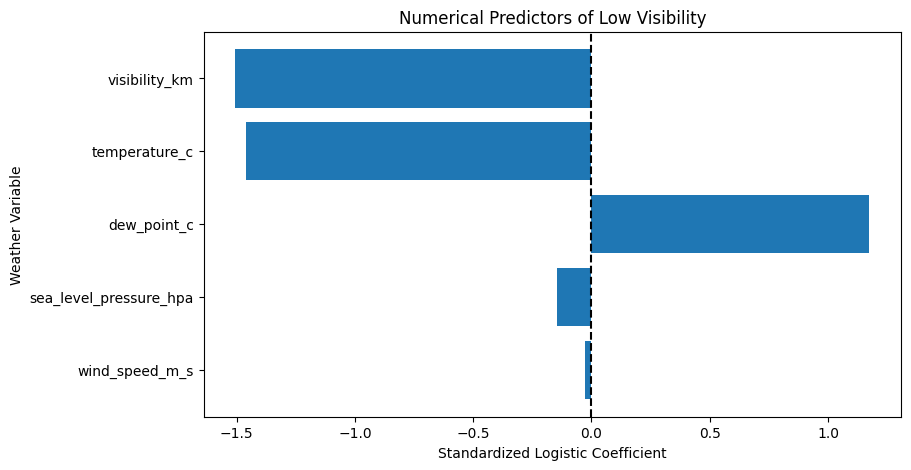

In [13]:

plt.figure(figsize=(9, 5))

plt.barh(
    coefficient_table["Feature"],
    coefficient_table["Coefficient"]
)

plt.axvline(0, color="black", linestyle="--")

plt.xlabel("Standardized Logistic Coefficient")
plt.ylabel("Weather Variable")
plt.title("Numerical Predictors of Low Visibility")

plt.gca().invert_yaxis()
plt.show()


In [14]:

def get_coefficients(fitted_model):
    prep = fitted_model.named_steps["columntransformer"]
    clf = fitted_model.named_steps["logisticregression"]

    scaler = prep.named_transformers_["numeric"].named_steps[
        "standardscaler"
    ]

    # Convert coefficients to original measurement units
    coefs = clf.coef_[0][:len(numeric_features)]
    return pd.Series(
        coefs / scaler.scale_,
        index=numeric_features
    )

coefficient_comparison = pd.DataFrame({
    "2008–2022": get_coefficients(validation_model),
    "2008–2023": get_coefficients(final_model)
})

coefficient_comparison["Difference"] = (
    coefficient_comparison["2008–2023"]
    - coefficient_comparison["2008–2022"]
)

display(coefficient_comparison.round(4))


,2008–2022,2008–2023,Difference
visibility_km,-0.4423,-0.4503,-0.0080
temperature_c,-0.1615,-0.1271,0.0344
dew_point_c,0.1425,0.1104,-0.0321
wind_speed_m_s,-0.0072,-0.0109,-0.0037
sea_level_pressure_hpa,-0.0174,-0.0196,-0.0021



### Temperature, Dew Point, and Dew-Point Depression

Our logistic regression results show that temperature and dew point have strong coefficients with opposite signs. Temperature has a negative coefficient, while dew point has a positive coefficient. This suggests that their relationship may be important when predicting low-visibility conditions.

**Dew point** is the temperature to which air must cool, at constant pressure and without changing its water vapor content, to reach saturation.

Air contains water vapor, which is water in its gaseous state. The amount of water vapor needed for saturation depends on temperature. Warmer air has a higher saturation vapor pressure than colder air.

**Saturation** occurs when the air's relative humidity reaches 100%. At this point, the air is in equilibrium with liquid water. If the air cools further, some water vapor can condense into liquid droplets, provided suitable conditions exist.

Condensation can contribute to several weather phenomena:

- **Fog:** Water vapor condenses into tiny droplets suspended near the ground, reducing visibility.
- **Clouds:** Condensation occurs higher in the atmosphere, forming cloud droplets.
- **Dew:** Water vapor condenses onto cool surfaces.
- **Rain:** Cloud droplets grow large enough to fall as precipitation. Saturation alone does not guarantee rainfall.

### Dew-Point Depression

The difference between air temperature and dew point is called **dew-point depression**:

$$
D = T - T_d
$$

Where:

- $D$ = Dew-point depression (°C)
- $T$ = Air temperature (°C)
- $T_d$ = Dew-point temperature (°C)

Dew-point depression measures **how much the air must cool to reach saturation**, assuming its moisture content and pressure remain constant.

For example, if the air temperature is 20°C and the dew point is 18°C, the dew-point depression is 2°C. This means the air must cool by approximately 2°C to reach saturation, assuming the dew point remains unchanged.

| Temperature | Dew Point | Depression | Interpretation |
|---|---|---|---|
| 20°C | 10°C | 10°C | Air must cool by 10°C to reach saturation |
| 20°C | 18°C | 2°C | Air must cool by 2°C to reach saturation |
| 20°C | 19.5°C | 0.5°C | Air is nearly saturated |

A smaller dew-point depression indicates that the air is closer to saturation. This means less cooling is required before condensation can occur.

### Relationship to Our Logistic Regression

The relationship between temperature and dew point helps explain their opposite regression coefficients.

- **Temperature (negative coefficient):** Holding dew point constant, higher temperatures increase dew-point depression and move the air farther from saturation.
- **Dew point (positive coefficient):** Holding temperature constant, higher dew points decrease dew-point depression and move the air closer to saturation.

These relationships are consistent with conditions that can support fog formation and reduced visibility.

However, temperature and dew point are correlated, which may affect the interpretation of their individual coefficients.

We can introduce dew-point depression as a single predictor to represent proximity to saturation more directly. Our next step is to compare the original logistic regression with a model that uses dew-point depression instead of temperature and dew point.


In [15]:
# Create copies of our existing feature datasets
X_train_dep = X_train.copy()
X_test_dep = X_test.copy()

# Calculate dew-point depression
for data in [X_train_dep, X_test_dep]:
    data["dew_point_depression_c"] = (
        data["temperature_c"] - data["dew_point_c"]
    )

# Select predictors for the new model
dep_numeric_features = [
    "visibility_km",
    "dew_point_depression_c",
    "wind_speed_m_s",
    "sea_level_pressure_hpa"
]

dep_features = dep_numeric_features + categorical_features

X_train_dep = X_train_dep[dep_features]
X_test_dep = X_test_dep[dep_features]


In [16]:
# Original model
original_model = clone(logistic_model)
original_model.fit(X_train, y_train)

# Dew-point depression preprocessing
dep_preprocessor = ColumnTransformer([
    ("numeric", make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler()
    ), dep_numeric_features),

    ("categorical", OneHotEncoder(
        drop="first",
        handle_unknown="ignore"
    ), categorical_features)
])

# New logistic regression
depression_model = make_pipeline(
    dep_preprocessor,
    LogisticRegression(max_iter=1000)
)

depression_model.fit(X_train_dep, y_train)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('columntransformer', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of

In [17]:

threshold = 0.25

models = {
    "Original": (original_model, X_test),
    "Dew-Point Depression": (depression_model, X_test_dep)
}

results = []

for name, (fitted_model, features) in models.items():
    probabilities = fitted_model.predict_proba(features)[:, 1]
    predicted = (probabilities >= threshold).astype(int)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predicted),
        "Precision": precision_score(y_test, predicted),
        "Recall": recall_score(y_test, predicted),
        "F1": f1_score(y_test, predicted),
        "ROC-AUC": roc_auc_score(y_test, probabilities),
        "Average Precision": average_precision_score(
            y_test, probabilities
        )
    })

comparison = pd.DataFrame(results).set_index("Model")

display(comparison.round(4))


,Accuracy,Precision,Recall,F1,ROC-AUC,Average Precision
Model,,,,,,
Original,0.9718,0.6091,0.7962,0.6902,0.9613,0.7611
Dew-Point Depression,0.9715,0.6049,0.7977,0.6880,0.9619,0.7597


In [18]:

# Only examine observations where visibility is normal now
normal_now = X_test["visibility_km"] >= 5
actual_onsets = y_test.loc[normal_now]

onset_results = []

for name, (fitted_model, features) in models.items():
    probabilities = fitted_model.predict_proba(
        features.loc[normal_now]
    )[:, 1]

    predicted = (probabilities >= threshold).astype(int)

    onset_results.append({
        "Model": name,
        "Precision": precision_score(
            actual_onsets, predicted, zero_division=0
        ),
        "Recall": recall_score(
            actual_onsets, predicted, zero_division=0
        ),
        "F1": f1_score(
            actual_onsets, predicted, zero_division=0
        )
    })

print("Actual onset observations:", actual_onsets.sum())

display(
    pd.DataFrame(onset_results)
    .set_index("Model")
    .round(4)
)


Actual onset observations: 203


,Precision,Recall,F1
Model,,,
Original,0.3056,0.3251,0.3150
Dew-Point Depression,0.2960,0.3251,0.3099
